In [537]:
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

from pathlib import Path

current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

## Set up the 2D example with trajectory sampling

In [538]:
# load in traj data

import pandas as pd

dataset = 6
session = 'A1821-190910' #'A1824-190827'

data_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data'

positions = pd.read_csv(data_path / 'Tracking_data.csv')
positions.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']

positions

,timestamp,x,y,hd,pitch,roll
0,3044.968,-0.130861,0.100300,33.84858,-35.82468,0.539701
1,3044.978,-0.130832,0.100818,34.52600,-36.17565,1.159622
2,3044.988,-0.130896,0.101376,35.51010,-36.44134,1.384442
3,3044.998,-0.130989,0.101857,35.95627,-35.95127,2.098573
4,3045.008,-0.131249,0.102067,35.85831,-36.34102,2.746262
...,...,...,...,...,...,...
541520,11547.110,0.228479,0.181418,46.24308,44.69220,23.492130
541521,11547.120,0.228509,0.181343,46.41534,44.59696,23.677580
541522,11547.130,0.228535,0.181324,46.83366,44.50164,23.561010
541523,11547.140,0.228546,0.181349,47.37060,44.32819,23.070700


In [539]:
from scipy.io.matlab._mio5_params import mat_struct
from scipy.io import loadmat

# make sure to filter by epochs
def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

epochs = loadmat(data_path / 'BehavEpochs.mat', struct_as_record=False, squeeze_me=True)
if dataset == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])


In [540]:


# filter by epoch
positions = positions[['timestamp', 'x', 'y', 'hd']].to_numpy()
position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]

# normalize x/y positions to be positive
positions[:, 1] += abs(np.min(positions[:, 1]))
positions[:, 2] += abs(np.min(positions[:, 2]))

len(positions)

270168

In [541]:
# Load in velocity data
velocity_data = []
vel_path = current_file_path / f'data/dusz/Dataset_{dataset}' / session / 'Data/Velocity.mat'
velocity_data = loadmat(vel_path, struct_as_record=False, squeeze_me=True)
        
velocity_data = extract_matlab_obj(velocity_data['vel'])
velocity_data = np.dstack((velocity_data['t'], velocity_data['data']))[0]
mask = (velocity_data[:, 0] > epoch_data['start']) & (velocity_data[:, 0] < epoch_data['stop'])
velocity_data = velocity_data[mask]

# velocity_data has shape (M, 3): [t, vx, vy] where speed = sqrt(vx**2 + vy**2)
vel_t   = velocity_data[:, 0]
vel_xy  = velocity_data[:, 1:3]
speed   = np.linalg.norm(vel_xy, axis=1)          # cm s-¹ I think this is unnecessary lol

# Interpolate speed at each position timestamp
pos_t   = positions[:, 0]
speed_at_pos = np.interp(pos_t, vel_t, speed, left=np.nan, right=np.nan)

speed_thresh = 5.0                               # cm s-¹
slow_mask = speed_at_pos < speed_thresh          # True where animal is < 5 cm/s

positions = positions[~slow_mask]


In [542]:
stimuli = (positions[:, 1], positions[:, 2])
labels = ("X position", "Y position")
limits = (0, max(np.max(stimuli[0]), np.max(stimuli[1])))

In [543]:
min_rate = 5.0
max_rate = 35.0
beta0     = np.log(min_rate)
amplitude = np.log(max_rate) - beta0

sigma = 0.07
lo, hi = limits
mu = 0.2 #(hi - lo) / 2 # tuning curve right in the center
num_bins = 9
N = 90_000
seed = 1
tau = 0.8

# you have time bins
# each time bin has a frequency associated with it
# you find which time bins belong to which spatial bin
# you average over the spikes for each of the applicable time bins

# so in this case we have a spike rate associated with a bin
# and we divide the base time up into bins 
# the question then is can we use a base time based on the positions? whatever

discrete_sample = False
real_trajectory_sample = True

def column_tuning(a, mu, sigma, amp):
    delta = np.abs(a - mu)
    return amp * np.exp(-(delta**2) / (2 * sigma**2))

if real_trajectory_sample:
    s1, s2 = stimuli
else:
    rng = np.random.default_rng(seed)
    s1 = rng.uniform(lo, hi, size=N)
    s2 = rng.uniform(lo, hi, size=N)

bin_edges = np.linspace(lo, hi, num_bins + 1)

if discrete_sample: 
    bin_width = (hi - lo) / num_bins
    s1_bin = np.clip(((s1 - lo) / bin_width).astype(int), 0, num_bins - 1)
    s2_bin = np.clip(((s2 - lo) / bin_width).astype(int), 0, num_bins - 1)
    
    s1 = lo + (s1_bin + 0.5) * bin_width  
    s2 = lo + (s2_bin + 0.5) * bin_width

tuning = column_tuning(s1, mu, sigma, amplitude)

# so now instead each bin should have its own firing rate and you're evaluating that on the poisson for however many times the time bin hits the spacial bin

rates  = np.exp(beta0 + tuning)
spike_counts = rng.poisson(rates) 

occ, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges])
spk, _, _ = np.histogram2d(s1, s2, bins=[bin_edges, bin_edges], weights=spike_counts)
rate_map = np.divide(spk, occ, out=np.zeros_like(spk), where=occ > 0)


In [548]:

def simulate_single_neuron_rate_map(
    timestamps,           
    stimuli,
    limits,               # (lo, hi) for both s1 and s2 (square env for simplicity)
    tau=0.8,              # counting window (s)
    num_bins=9,           # spatial bins per axis
    mu=0.2,               # preferred stimulus location along s1 axis (same units as s1)
    sigma=0.07,           # width of the tuning along s1
    min_rate=5.0,         # baseline (spikes/s)
    max_rate=35.0,        # peak (spikes/s)
    seed=1
):
    rng = np.random.default_rng(seed)
    lo, hi = limits

    pos_ts = positions[:, 0]
    s1, s2 = stimuli

    # τ windows over the recording
    t0, t1 = float(pos_ts[0]), float(pos_ts[-1])
    base_time = np.arange(t0, t1, tau)

    # Nearest recorded sample to the *left edge* (keeps behavior close to your original)
    # If you prefer window centers, change to tc = base_time + tau/2.
    idx = np.clip(np.searchsorted(pos_ts, base_time, side='left'), 0, len(pos_ts)-1)
    s1_t = s1[idx]
    s2_t = s2[idx]

    # --- Tuning curve (log-link for min/max) along s1 only ---------------------
    beta0     = np.log(min_rate)
    amplitude = np.log(max_rate) - beta0

    def column_tuning(a, mu, sigma, amp):
        # Gaussian bump on s1; returns an additive term in log-rate space
        delta = np.abs(a - mu)
        return amp * np.exp(-0.5 * (delta / sigma)**2)

    tuning = column_tuning(s1_t, mu, sigma, amplitude)
    lam_t  = np.exp(beta0 + tuning)           # spikes/s per τ-bin
    lam_t  = np.clip(lam_t, 0.0, None)

    # --- Sample Poisson counts for each τ window ------------------------------
    lam_dt = lam_t * tau                       # expected spikes in the bin
    counts = rng.poisson(lam_dt)               # integer spikes per τ-bin
    total_spikes = int(counts.sum())

    # Build [timestamp, neuron_id] with uniform jitter within each τ window
    if total_spikes == 0:
        spike_times = np.empty((0, 2), dtype=float)
    else:
        bin_starts = np.repeat(base_time, counts)          # one start time per spike
        jitter     = rng.uniform(0.0, tau, size=total_spikes)
        spike_ts   = bin_starts + jitter
        neuron_id  = np.zeros(total_spikes, dtype=float)   # single neuron -> id = 0.0
        spike_times = np.column_stack((spike_ts, neuron_id))
        # sort by time (optional)
        order = np.argsort(spike_times[:, 0])
        spike_times = spike_times[order]

    # --- Build rate map like your pipeline: spikes per second per spatial bin --
    bin_edges = np.linspace(lo, hi, num_bins + 1)

    # Occupancy in seconds per bin (weight each τ-visit by tau seconds)
    occ_seconds, _, _ = np.histogram2d(
        s1_t, s2_t, bins=[bin_edges, bin_edges],
        weights=np.full_like(s1_t, fill_value=tau, dtype=float)
    )

    # Spike counts per bin (weight each τ-visit by the count in that window)
    spk_counts, _, _ = np.histogram2d(
        s1_t, s2_t, bins=[bin_edges, bin_edges],
        weights=counts.astype(float)
    )

    # spikes/s = (total spikes in bin) / (total seconds spent in bin)
    rate_map = np.divide(
        spk_counts, occ_seconds,
        out=np.full_like(spk_counts, np.nan, dtype=float),
        where=occ_seconds > 0
    )

    return spike_times, rate_map, occ_seconds, bin_edges, base_time, s1_t, s2_t

In [551]:
spike_times, rate_map, occ_seconds, bin_edges, base_time, s1_t, s2_t = simulate_single_neuron_rate_map(
    positions[:, 0],           
    stimuli,
    limits,               # (lo, hi) for both s1 and s2 (square env for simplicity)
    tau=0.8,              # counting window (s)
    num_bins=9,           # spatial bins per axis
    mu=0.2,               # preferred stimulus location along s1 axis (same units as s1)
    sigma=0.07,           # width of the tuning along s1
    min_rate=5.0,         # baseline (spikes/s)
    max_rate=35.0,        # peak (spikes/s)
    seed=1)

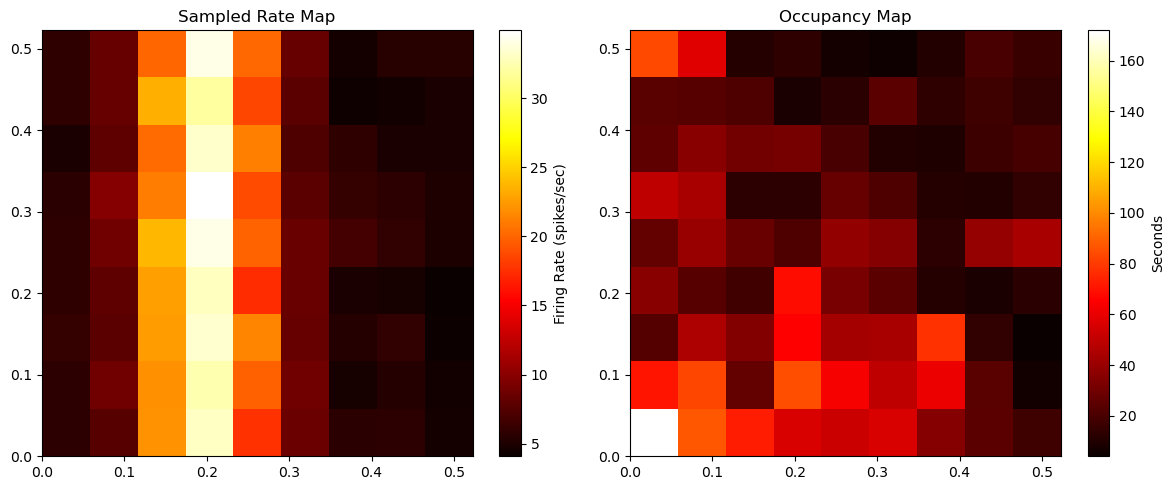

In [553]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(rate_map.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(occ_seconds.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[1].set_title(f"Occupancy Map")
fig.colorbar(im2, ax=axs[1], label='Seconds')

plt.tight_layout()
plt.show()


## Now let's take a look at the 1d

In [545]:
max_bin_occ = int(np.max(occ))

raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan) 

for s1_i in range(num_bins):
    for s2_i in range(num_bins):
        visits_indexes = (s1 >= bin_edges[s1_i]) & (s1 < bin_edges[s1_i + 1])
        visits_indexes &= (s2 >= bin_edges[s2_i]) & (s2 < bin_edges[s2_i + 1])
        spikes_bin = spike_counts[visits_indexes]
        
        raw_visits[s1_i, s2_i, :len(spikes_bin)] = spikes_bin

In [459]:
slice_1d = 4 #num_bins // 2

rate_map_1d = rate_map[slice_1d]
occ_1d = occ[slice_1d]
raw_visits_1d = raw_visits[slice_1d]

rate_map_1d

array([6.6462963 , 6.87657658, 6.87198516, 6.79506641, 6.76021798,
       6.81073944, 6.8516791 , 6.705365  , 6.78035714])

In [424]:
slice_1d

4

In [425]:
rate_map_1d.mean()

33.21176220597359

In [546]:
# redefining these here so that they can be tweaked as needed

# 1d version
def get_splits(
        visits, # s1_dim, n_max_visits, n_neurons
        min_visits=2,
        cap=False,
        seed=None
):
    rng = np.random.default_rng(seed)
    num_bins = visits.shape[0]

    # half = cap // 2
    n_neurons = visits.shape[2]

    total_mean = np.full((num_bins, n_neurons), np.nan)
    train_mean = np.full((num_bins, n_neurons), np.nan)
    test_mean  = np.full((num_bins, n_neurons), np.nan)
    train_occ  = np.full((num_bins), 0)
    test_occ   = np.full((num_bins), 0)

    for s1 in range(visits.shape[0]):
        for n in range(visits.shape[2]):
            n_visits = np.count_nonzero(~np.isnan(visits[s1, :, n]))
            if n_visits >= min_visits:
                take_n = min_visits if cap else n_visits
                visit_split = visits[s1, :take_n, n]
                rng.shuffle(visit_split)
                half = len(visit_split) // 2
                train = visit_split[:half]
                test = visit_split[half:]
                if len(visit_split) % 2 != 0:
                    test = test[:-1]
                    
                train_mean[s1, n] = train.mean()
                test_mean[s1, n] = test.mean()
                total_mean[s1, n] = visit_split.mean()
                train_occ[s1], test_occ[s1] = half, half

    return total_mean, train_mean, test_mean, train_occ, test_occ

def quantify_variance_1d(heatmap_test, heatmap_train, verbose=False):
    # heatmap_test and heatmap_train are average spikes/sec per behavioral bin
    
    test_mean = np.nanmean(heatmap_test)
    train_mean = np.nanmean(heatmap_train)

    n_bins = heatmap_test.shape[0]

    inter_var_test = np.nansum((heatmap_test - test_mean)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * (test_mean - train_mean)**2

    if verbose:
        print(f"sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"sum((test - train)^2)={intra_var_all:.4f}")
        print(f"n_bins * (test_mean - train_mean)^2={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means

def calculate_explained_variance_2d_weighted(
    heatmap_train, heatmap_test,
    occupancy_train, occupancy_test,
    axis, verbose=False
):
    """
    Calculates debiased explained variance using an occupancy-weighted average
    to correct for non-uniform sampling. This is the robust method for real data.

    axis=0: Analyzes variable on rows (s1).
    axis=1: Analyzes variable on columns (s2).
    """
    marginal_axis_to_average = 1 if axis == 0 else 0

    # --- Calculate Weighted Marginals (The Correct Way) ---
    # Numerator: rate * occupancy = total spikes in slice
    # Denominator: total occupancy in slice
    
    # For train set
    f_bar_num = np.nansum(heatmap_train * occupancy_train, axis=marginal_axis_to_average, keepdims=True)
    f_bar_den = np.nansum(occupancy_train, axis=marginal_axis_to_average, keepdims=True)
    f_bar = np.divide(f_bar_num, f_bar_den, out=np.full_like(f_bar_num, np.nan), where=f_bar_den>0)

    # For test set
    ft_bar_num = np.nansum(heatmap_test * occupancy_test, axis=marginal_axis_to_average, keepdims=True)
    ft_bar_den = np.nansum(occupancy_test, axis=marginal_axis_to_average, keepdims=True)
    ft_bar = np.divide(ft_bar_num, ft_bar_den, out=np.full_like(ft_bar_num, np.nan), where=ft_bar_den>0)

    # --- The Estimator Formula ---
    term1 = (heatmap_train - f_bar)**2
    term2 = (heatmap_test - ft_bar)**2
    term3 = (heatmap_test - heatmap_train)**2
    term4 = (f_bar - ft_bar)**2

    # The sum over all bins is unweighted, as per the original formula's structure.
    # The weighting has already corrected the marginals, which is the critical step.
    total_sum = np.nansum(term1 + term2 - term3 + term4)
    estimator = 0.5 * total_sum
    
    return estimator

In [547]:
def get_splits(
        visits, # s1_dim, s2_dim, n_max_visits, n_neurons
        min_visits=2,
        cap=False,
        seed=None
):
    """
    Randomly halves the samples in each bin → train / test splits.

    Returns
    -------
    train_mean, test_mean : mean spike count in each bin (nan if <min_visits)
    train_occ,  test_occ  : visit counts assigned to each split
    """
    rng = np.random.default_rng(seed)
    num_bins = visits.shape[0]

    # half = cap // 2
    n_neurons = visits.shape[3]

    total_mean = np.full((num_bins, num_bins, n_neurons), np.nan)
    train_mean = np.full((num_bins, num_bins, n_neurons), np.nan)
    test_mean  = np.full((num_bins, num_bins, n_neurons), np.nan)
    train_occ  = np.full((num_bins, num_bins), 0)
    test_occ   = np.full((num_bins, num_bins), 0)

    for s1 in range(visits.shape[0]):
        for s2 in range(visits.shape[1]):
            for n in range(visits.shape[3]):
                n_visits = np.count_nonzero(~np.isnan(visits[s1, s2, :, n]))
                if n_visits >= min_visits:
                    take_n = min_visits if cap else n_visits
                    visit_split = visits[s1, s2, :take_n, n]#[s1, s2, :cap, n]
                    rng.shuffle(visit_split)
                    half = len(visit_split) // 2
                    train, test = visit_split[:half], visit_split[half:]
                    
                    train_mean[s1, s2, n] = train.mean()
                    test_mean[s1,  s2, n] = test.mean()
                    total_mean[s1, s2, n] = visit_split.mean()
                    train_occ[s1, s2] = len(train)
                    test_occ[s1, s2] = len(test)
                else:
                    train_occ[s1, s2, n] = 0
                    test_occ[s1, s2, n] = 0

    return total_mean, train_mean, test_mean, train_occ, test_occ

In [578]:
import numpy as np

def build_raw_visits_and_folds(s1_t, s2_t, counts, tau, num_bins, bin_edges, seed=111):
    """
    Inputs are per-τ-window:
      s1_t, s2_t : arrays of positions (one per τ window)
      counts     : integer spike counts for each τ window
      tau        : window length (s)
      num_bins   : spatial bins per axis
      bin_edges  : 1D array of bin edges (len = num_bins + 1), same for s1 and s2

    Returns:
      raw_visits   : (num_bins, num_bins, max_bin_occ) visit rates (spikes/s), NaN-padded
      fold0_map    : (num_bins, num_bins) spikes/s, mean over fold-0 visits in each bin
      fold1_map    : (num_bins, num_bins) spikes/s, mean over fold-1 visits in each bin
      occ_visits   : (num_bins, num_bins) number of visits (τ windows) per bin
      occ_seconds  : (num_bins, num_bins) occupancy seconds per bin (= occ_visits * tau)
    """
    rng = np.random.default_rng(seed)

    # Per-visit rates (spikes/s)
    visit_rates = counts.astype(float) / float(tau)

    # Bin indices for each visit; mask out-of-range (rightmost edge)
    i = np.digitize(s1_t, bin_edges) - 1
    j = np.digitize(s2_t, bin_edges) - 1
    in_range = (i >= 0) & (i < num_bins) & (j >= 0) & (j < num_bins)

    i = i[in_range]
    j = j[in_range]
    visit_rates = visit_rates[in_range]

    # Occupancy in "visits" and in seconds
    occ_visits, _, _ = np.histogram2d(
        s1_t[in_range], s2_t[in_range], bins=[bin_edges, bin_edges]
    )
    occ_visits = occ_visits.astype(int)
    occ_seconds = occ_visits * float(tau)

    max_bin_occ = int(occ_visits.max()) if occ_visits.size else 0
    max_bin_occ = (max_bin_occ // 2) + 1

    fold0_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan, dtype=float)
    fold1_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan, dtype=float)

    # Build an index list per bin to avoid O(N*M^2) scans
    # Map (i,j) -> list of indices for visits in that bin
    bin_lists = [[[] for _ in range(num_bins)] for _ in range(num_bins)]
    # Enumerate visits and push their indices into the right bin
    for idx_visit, (ii, jj) in enumerate(zip(i, j)):
        bin_lists[ii][jj].append(idx_visit)

    # Fill raw_visits and compute folds
    for ii in range(num_bins):
        for jj in range(num_bins):
            idxs = bin_lists[ii][jj]
            if not idxs:
                continue
            rates_ij = visit_rates[idxs]

            n_ij = len(rates_ij)

            perm = rng.permutation(n_ij)
            half = n_ij // 2
            fold0 = rates_ij[perm[:half]] if half > 0 else np.array([], dtype=float)
            fold1 = rates_ij[perm[half:]]  # remainder (>= half)

            if fold0.size > 0:
                fold0_visits[ii, jj, :fold0.size] = fold0
            if fold1.size > 0:
                fold1_visits[ii, jj, :fold1.size] = fold1

    return fold0_visits, fold1_visits, occ_visits, occ_seconds


In [625]:


from scipy.ndimage import gaussian_filter, zoom

smooth_sigma = 1.
upsample_factor = 2

counts = np.zeros_like(base_time, dtype=int)
bin_idx = np.searchsorted(base_time, spike_times[:, 0], side='right') - 1
valid = (bin_idx >= 0) & (bin_idx < len(base_time)) & (spike_times[:, 0] < base_time[bin_idx] + tau)
np.add.at(counts, bin_idx[valid], 1)

n_splits = 70
bins_range = range(5, 20)

# results: dict[num_bins] -> (n_splits,) EVs
est_var_by_bins = {n: np.full(n_splits, np.nan, dtype=float) for n in bins_range}
est_var_selective = {n: np.full(n_splits, np.nan, dtype=float) for n in bins_range}
est_var_by_bins_zoom = {n: np.full(n_splits, np.nan, dtype=float) for n in bins_range}
est_var_selective_zoom = {n: np.full(n_splits, np.nan, dtype=float) for n in bins_range}

for num_bins in tqdm(bins_range, desc="Sweeping spatial bin counts"):
    bin_edges = np.linspace(lo, hi, num_bins + 1)

    for i in range(n_splits):
        fold0_visits, fold1_visits, occ_visits, occ_seconds2 = build_raw_visits_and_folds(
            s1_t=s1_t, s2_t=s2_t, counts=counts, tau=tau,
            num_bins=num_bins, bin_edges=bin_edges, seed=i  # vary seed per split
        )

        fold0_map = np.nanmean(fold0_visits, axis=2)
        fold1_map = np.nanmean(fold1_visits, axis=2)

        est_var_by_bins[num_bins][i] = quantify_variance(fold0_map, fold1_map, axis=1, verbose=False)[0]
        est_var_selective[num_bins][i] = quantify_variance(fold0_map, fold1_map, axis=0, verbose=False)[0]

        fold0_smooth = gaussian_filter(fold0_map, sigma=smooth_sigma)
        fold1_smooth = gaussian_filter(fold1_map, sigma=smooth_sigma)

        fold0_fine = zoom(fold0_smooth, upsample_factor, order=2)
        fold1_fine = zoom(fold1_smooth, upsample_factor, order=2)
        
        est_var_by_bins_zoom[num_bins][i] = quantify_variance(fold0_fine, fold1_fine, axis=1, verbose=False)[0]
        est_var_selective_zoom[num_bins][i] = quantify_variance(fold0_fine, fold1_fine, axis=0, verbose=False)[0]
        

# optional quick summaries
mean_ev_by_bins = {n: np.nanmean(v) for n, v in est_var_by_bins.items()}
std_ev_by_bins  = {n: np.nanstd(v, ddof=1) for n, v in est_var_by_bins.items()}

mean_ev_selective = {n: np.nanmean(v) for n, v in est_var_selective.items()}
std_ev_selective  = {n: np.nanstd(v, ddof=1) for n, v in est_var_selective.items()}

mean_ev_by_bins_zoom = {n: np.nanmean(v) for n, v in est_var_by_bins_zoom.items()}
std_ev_by_bins_zoom  = {n: np.nanstd(v, ddof=1) for n, v in est_var_by_bins_zoom.items()}

mean_ev_selective_zoom = {n: np.nanmean(v) for n, v in est_var_selective_zoom.items()}
std_ev_selective_zoom  = {n: np.nanstd(v, ddof=1) for n, v in est_var_selective_zoom.items()}

Sweeping spatial bin counts:  47%|██████████████████████████████████████████████████████████████████████▍                                                                                | 7/15 [00:01<00:01,  6.29it/s]/tmp/ipykernel_1125317/3235621524.py:29: RuntimeWarning: Mean of empty slice
  fold0_map = np.nanmean(fold0_visits, axis=2)
Sweeping spatial bin counts:  60%|██████████████████████████████████████████████████████████████████████████████████████████▌                                                            | 9/15 [00:01<00:01,  5.83it/s]/tmp/ipykernel_1125317/3235621524.py:30: RuntimeWarning: Mean of empty slice
  fold1_map = np.nanmean(fold1_visits, axis=2)
Sweeping spatial bin counts: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 15/15 [00:02<00:00,  5.48it/s]


In [607]:
mean_ev_by_bins

{5: 27.240106429132066,
 6: 23.90729980402272,
 7: 44.77519671533472,
 8: 1.7806741925210037,
 9: -9.252119413278612,
 10: 99.47683015317116,
 11: 79.48682822001763,
 12: 99.4593995373144,
 13: 37.81851117116852,
 14: 159.16481138103052,
 15: 104.17141862214581,
 16: 263.335990768015,
 17: 347.38578574040594,
 18: 299.68939761464054,
 19: 384.09848297298527}

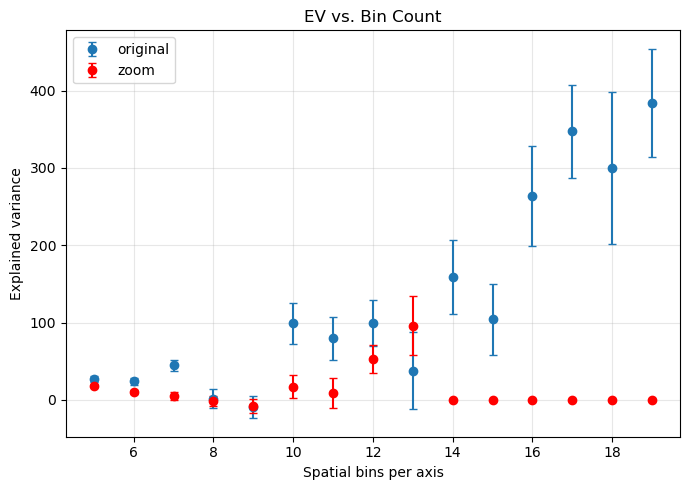

In [626]:
import numpy as np
import matplotlib.pyplot as plt

# --- Original series ---
bins_orig  = np.array(sorted(mean_ev_by_bins.keys()))
means_orig = np.array([mean_ev_by_bins[n] for n in bins_orig])
stds_orig  = np.array([std_ev_by_bins[n]  for n in bins_orig])

# --- Zoom series ---
bins_zoom  = np.array(sorted(mean_ev_by_bins_zoom.keys()))
means_zoom = np.array([mean_ev_by_bins_zoom[n] for n in bins_zoom])
stds_zoom  = np.array([std_ev_by_bins_zoom[n]  for n in bins_zoom])

plt.figure(figsize=(7,5))

# Original points (default color)
plt.errorbar(
    bins_orig, means_orig, yerr=stds_orig,
    fmt='o', capsize=3, label='original'
)

# Zoom points (red)
plt.errorbar(
    bins_zoom, means_zoom, yerr=stds_zoom,
    fmt='o', capsize=3, color='red', ecolor='red', label='zoom'
)

plt.xlabel('Spatial bins per axis')
plt.ylabel('Explained variance')
plt.title('EV vs. Bin Count')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# look into this nan issue carefully because even if you have just one bin with 
# which part creates the issue,
# smooth R/O sep
# try out more random seeds for the real data


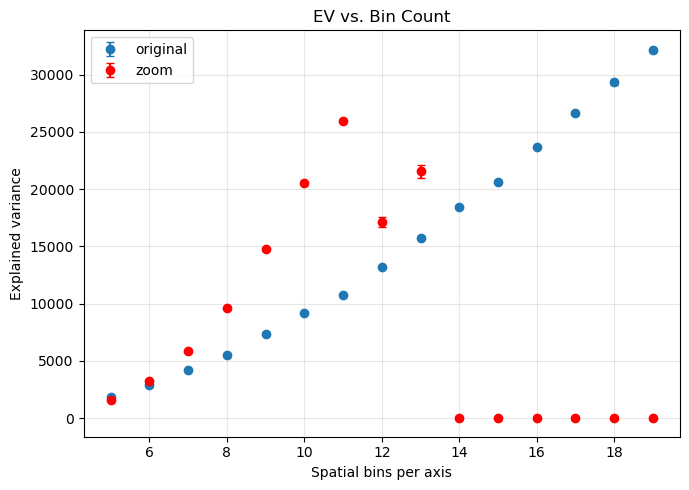

In [627]:
import numpy as np
import matplotlib.pyplot as plt

# --- Original series ---
bins_orig  = np.array(sorted(mean_ev_selective.keys()))
means_orig = np.array([mean_ev_selective[n] for n in bins_orig])
stds_orig  = np.array([std_ev_selective[n]  for n in bins_orig])

# --- Zoom series ---
bins_zoom  = np.array(sorted(mean_ev_by_bins_zoom.keys()))
means_zoom = np.array([mean_ev_selective_zoom[n] for n in bins_zoom])
stds_zoom  = np.array([std_ev_selective_zoom[n]  for n in bins_zoom])

plt.figure(figsize=(7,5))

# Original points (default color)
plt.errorbar(
    bins_orig, means_orig, yerr=stds_orig,
    fmt='o', capsize=3, label='original'
)

# Zoom points (red)
plt.errorbar(
    bins_zoom, means_zoom, yerr=stds_zoom,
    fmt='o', capsize=3, color='red', ecolor='red', label='zoom'
)

plt.xlabel('Spatial bins per axis')
plt.ylabel('Explained variance')
plt.title('EV vs. Bin Count')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# look into this nan issue carefully because even if you have just one bin with 
# which part creates the issue,
# smooth R/O sep
# try out more random seeds for the real data


In [574]:
import numpy as np
from scipy.optimize import minimize
from tqdm import tqdm

# ---------- Gaussian fit per fold (Poisson) -----------------------------------
def _gauss2d_axis_aligned(x, y, mux, muy, sx, sy):
    # returns exp(-0.5*((x-mux)/sx)^2 -0.5*((y-muy)/sy)^2)
    return np.exp(-0.5 * (((x - mux) / sx) ** 2 + ((y - muy) / sy) ** 2))

def fit_gaussian_fold_to_visits(s1v, s2v, kv, tau, limits, num_bins,
                                init_sigma_bins=1.5, rng=None):
    """
    Fit baseline+amplitude*Gaussian(x,y) to visit counts kv (Poisson with mean lam*tau).
    Returns a rate map evaluated at bin centers (spikes/s) and fitted params.
    """
    lo, hi = limits
    if rng is None:
        rng = np.random.default_rng()
    s1v = np.asarray(s1v, float); s2v = np.asarray(s2v, float); kv = np.asarray(kv, float)
    n = len(kv)

    # Fallback if too few visits to fit robustly
    if n < 6:
        # Build naive mean-of-visits map as a safe fallback
        bin_edges = np.linspace(lo, hi, num_bins + 1)
        occ_sec, _, _ = np.histogram2d(s1v, s2v, bins=[bin_edges, bin_edges],
                                       weights=np.full(n, tau))
        spk_cnt, _, _ = np.histogram2d(s1v, s2v, bins=[bin_edges, bin_edges],
                                       weights=kv)
        rate_map = np.divide(spk_cnt, occ_sec, out=np.full_like(spk_cnt, np.nan), where=occ_sec > 0)
        return rate_map, dict(fallback=True)

    # Initial guesses
    bin_w = (hi - lo) / num_bins
    rates = kv / float(tau)
    mux0 = np.average(s1v, weights=np.clip(rates, 1e-6, None))
    muy0 = np.average(s2v, weights=np.clip(rates, 1e-6, None))
    sx0  = init_sigma_bins * bin_w
    sy0  = init_sigma_bins * bin_w
    base0 = max(1e-3, np.percentile(rates, 10.0))
    amp0  = max(1e-3, rates.max() - base0)

    # Parameterization: [baseline, amplitude, mux, muy, log_sx, log_sy]
    def unpack(theta):
        b, A, mx, my, lxs, lys = theta
        return b, A, mx, my, np.exp(lxs), np.exp(lys)

    # Poisson negative log-likelihood
    def nll(theta):
        b, A, mx, my, sx, sy = unpack(theta)
        # Enforce positivity softly
        if b < 0 or A < 0 or sx <= 0 or sy <= 0 or not (lo <= mx <= hi) or not (lo <= my <= hi):
            return 1e50
        g = _gauss2d_axis_aligned(s1v, s2v, mx, my, sx, sy)
        lam = b + A * g  # spikes/s
        lam = np.clip(lam, 1e-9, None)
        mu = lam * float(tau)  # expected counts
        # Sum(mu - k*log(mu))  (const term log(k!) dropped)
        return np.sum(mu - kv * np.log(mu))

    theta0 = np.array([base0, amp0, mux0, muy0, np.log(sx0), np.log(sy0)], dtype=float)
    bounds = [
        (1e-9, None),      # baseline
        (0.0,   None),     # amplitude
        (lo,    hi),       # mux
        (lo,    hi),       # muy
        (np.log(0.25*bin_w), np.log(5.0*(hi - lo))),  # log_sx
        (np.log(0.25*bin_w), np.log(5.0*(hi - lo))),  # log_sy
    ]
    res = minimize(nll, theta0, method='L-BFGS-B', bounds=bounds, options=dict(maxiter=500))
    b, A, mx, my, sx, sy = unpack(res.x)

    # Evaluate at bin centers
    centers = 0.5 * (np.linspace(lo, hi, num_bins + 1)[:-1] + np.linspace(lo, hi, num_bins + 1)[1:])
    Xc, Yc = np.meshgrid(centers, centers, indexing='ij')
    ggrid = _gauss2d_axis_aligned(Xc, Yc, mx, my, sx, sy)
    rate_map = b + A * ggrid  # spikes/s
    return rate_map, dict(baseline=b, amplitude=A, mux=mx, muy=my, sx=sx, sy=sy, success=res.success)

# ---------- Sweep with per-fold Gaussian fits ---------------------------------
# Assumes in scope: s1_t, s2_t, counts, tau, lo, hi, quantify_variance

n_splits   = 300
bins_range = range(5, 101)  # 5..100 inclusive

ev_gaussfit_by_bins = {n: np.full(n_splits, np.nan) for n in bins_range}

for num_bins in tqdm(bins_range, desc="Sweeping bins with fold-wise Gaussian fits"):
    bin_edges = np.linspace(lo, hi, num_bins + 1)

    # Precompute per-visit bin indices (for fold-balanced splitting)
    ii = np.digitize(s1_t, bin_edges) - 1
    jj = np.digitize(s2_t, bin_edges) - 1
    in_range = (ii >= 0) & (ii < num_bins) & (jj >= 0) & (jj < num_bins)

    ii_f = ii[in_range]; jj_f = jj[in_range]
    s1_f = s1_t[in_range]; s2_f = s2_t[in_range]; k_f = counts[in_range]

    # Build bin->visit index lists so each split can balance by bin
    bin_lists = [[[] for _ in range(num_bins)] for _ in range(num_bins)]
    for k_idx, (bi, bj) in enumerate(zip(ii_f, jj_f)):
        bin_lists[bi][bj].append(k_idx)

    for split_idx in range(n_splits):
        rng = np.random.default_rng(split_idx)

        # Accumulate per-fold visit indices (balanced within each spatial bin)
        idxs0, idxs1 = [], []
        for bi in range(num_bins):
            for bj in range(num_bins):
                idxs = bin_lists[bi][bj]
                if not idxs:
                    continue
                perm = rng.permutation(len(idxs))
                half = len(idxs) // 2
                idxs0.extend([idxs[p] for p in perm[:half]])
                idxs1.extend([idxs[p] for p in perm[half:]])

        idxs0 = np.array(idxs0, dtype=int)
        idxs1 = np.array(idxs1, dtype=int)

        # Fit Gaussian to each fold's visits, evaluate at bin centers
        fold0_map_fit, _p0 = fit_gaussian_fold_to_visits(
            s1_f[idxs0], s2_f[idxs0], k_f[idxs0], tau, (lo, hi), num_bins,
            init_sigma_bins=1.5, rng=rng
        )
        fold1_map_fit, _p1 = fit_gaussian_fold_to_visits(
            s1_f[idxs1], s2_f[idxs1], k_f[idxs1], tau, (lo, hi), num_bins,
            init_sigma_bins=1.5, rng=rng
        )

        # Compute EV using your method
        ev = quantify_variance(fold0_map_fit, fold1_map_fit, axis=1, verbose=False)
        ev_gaussfit_by_bins[num_bins][split_idx] = ev[0] if np.ndim(ev) else ev


Sweeping bins with fold-wise Gaussian fits:   8%|███████████▎                                                                                                                            | 8/96 [03:41<40:38, 27.72s/it]


KeyboardInterrupt: 

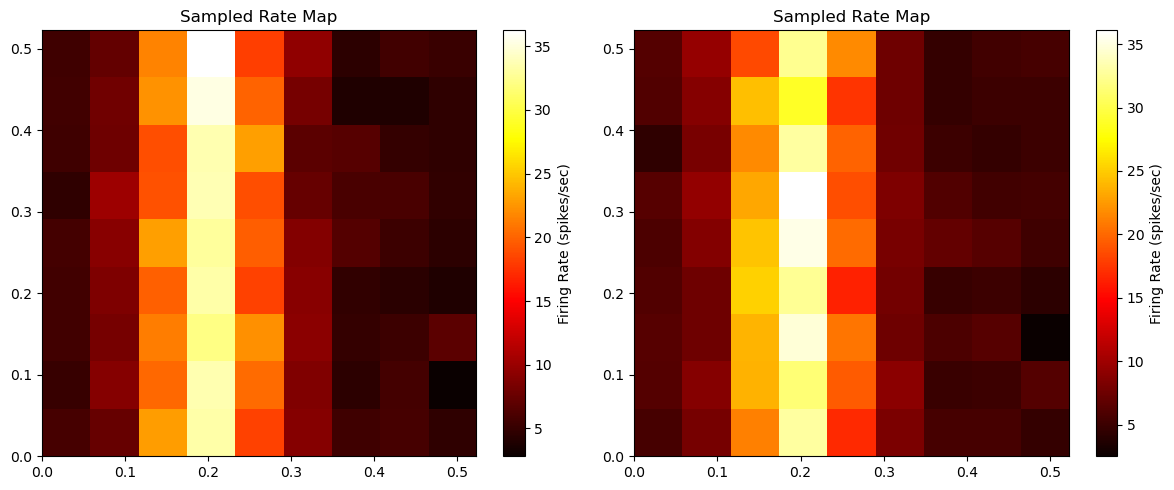

In [567]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Rate map
im1 = axs[0].imshow(fold0_map.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[0].set_title("Sampled Rate Map")
fig.colorbar(im1, ax=axs[0], label='Firing Rate (spikes/sec)')

# Occupancy map
im2 = axs[1].imshow(fold1_map.T, origin='lower', aspect='auto',
                     extent=[bin_edges[0], bin_edges[-1], bin_edges[0], bin_edges[-1]],
                     cmap='hot')
axs[1].set_title("Sampled Rate Map")
fig.colorbar(im2, ax=axs[1], label='Firing Rate (spikes/sec)')

plt.tight_layout()
plt.show()


In [533]:
from tqdm import tqdm
from src.methods import quantify_variance
from scipy.ndimage import gaussian_filter

n_splits = 30
est_var = np.zeros((n_splits))

sigma = ((hi - lo) / n_bins) * 2
n_secondary_bins = 30 # number of bins to evaluate the smoothed map at

print("Sigma:", sigma)

for i in tqdm(range(n_splits)):
    rates = np.exp(beta0 + tuning)
    spike_counts = rng.poisson(rates)
    
    # collect raw visit map
    max_bin_occ = int(np.max(occ))

    raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan) 
    
    for s1_i in range(num_bins):
        for s2_i in range(num_bins):
            visits_indexes = (s1 >= bin_edges[s1_i]) & (s1 < bin_edges[s1_i + 1])
            visits_indexes &= (s2 >= bin_edges[s2_i]) & (s2 < bin_edges[s2_i + 1])
            spikes_bin = spike_counts[visits_indexes]
            
            raw_visits[s1_i, s2_i, :len(spikes_bin)] = spikes_bin

    slice_1d = 8 #num_bins // 2

    raw_visits_1d = raw_visits#[slice_1d]
    
    total_mean, train_mean, test_mean, train_occ, test_occ = get_splits(raw_visits_1d[:, :, :, np.newaxis], min_visits=2, cap=False, seed=i)

    gaussian_filter(train_mean, sigma=sigma)
    
    #est_var[i] = quantify_variance_1d(train_mean, test_mean)[0]
    est_var[i] = calculate_explained_variance_2d_weighted(train_mean[:, :, 0], test_mean[:, :, 0], train_occ, test_occ, axis=1, verbose=False)#[0]
    #est_var[i] = quantify_variance(train_mean[:, :, 0], test_mean[:, :, 0], axis=0, verbose=False)[0]
    #est_var[i] = calculate_explained_variance_1d_weighted(train_mean, test_mean, train_occ, test_occ)



100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:03<00:00,  8.76it/s]


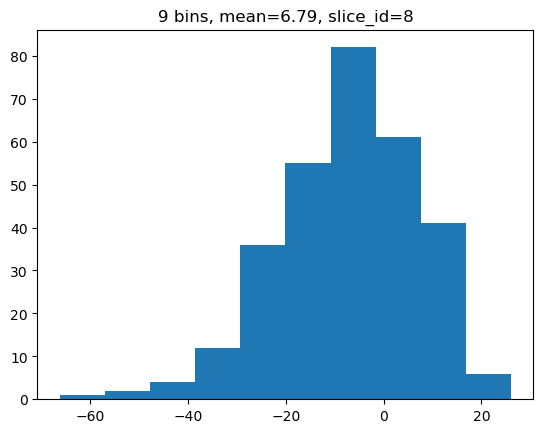

In [564]:
plt.hist(est_var)
plt.title(f'{num_bins} bins, mean={rate_map_1d.mean():.2f}, slice_id={slice_1d}')
plt.show()

# the normal one ends up being around 7220 for the selective, 11 for the nonselective
# the occ weighted one is exactly the same.

In [558]:
est_var

array([7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516, 7190.44224516, 7190.44224516,
       7190.44224516, 7190.44224516])

In [359]:
def var_mean(x):
    m = np.nanmean(x)
    return np.nanmean((x - m)**2)

def var_mean_diff(x, y):
    return np.nanmean((x - y)**2)

def quantify_variance_1d_density_invariant(test, train):
    # all terms are *means* of squared deviations, not sums
    inter_var_test  = var_mean(test)
    inter_var_train = var_mean(train)
    intra_var_all   = var_mean_diff(test, train)
    # the mean-difference correction is now just squared difference of means
    intra_var_means = (np.nanmean(test) - np.nanmean(train))**2

    estimator = 0.5 * (inter_var_test + inter_var_train - intra_var_all + intra_var_means)
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means


In [410]:
from scipy.stats import gaussian_kde

n_splits = 100
est_var  = np.zeros(n_splits)

def quantify_variance_1d(heatmap_test, heatmap_train, verbose=False):
    # heatmap_test and heatmap_train are average spikes/sec per behavioral bin
    
    test_mean = np.nanmean(heatmap_test)
    train_mean = np.nanmean(heatmap_train)

    n_bins = heatmap_test.shape[0]

    inter_var_test = np.nansum((heatmap_test - test_mean)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * (test_mean - train_mean)**2

    if verbose:
        print(f"sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"sum((test - train)^2)={intra_var_all:.4f}")
        print(f"n_bins * (test_mean - train_mean)^2={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means

bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2  # (num_bins,)

interp = True

n_interp_bins = 9 # original num_bins is 9
interp_bin_edges    = np.linspace(limits[0], limits[1], num=n_interp_bins + 1)
interp_bin_centers  = (interp_bin_edges[:-1] + interp_bin_edges[1:]) / 2  # (n_interp_bins,)

# pick a 1-D slice along s1 (fix s2 index)
slice_1d = 3  # or num_bins // 2

# --- 3) Main loop ---
for i in tqdm(range(n_splits)):
    # simulate spikes per-visit (your code)
    rates        = np.exp(beta0 + tuning)
    spike_counts = rng.poisson(rates)

    max_bin_occ = int(np.max(occ))
    raw_visits = np.full((num_bins, num_bins, max_bin_occ), np.nan)
    
    for s1_i in range(num_bins):
        for s2_i in range(num_bins):
            visits_indexes  = (s1 >= bin_edges[s1_i]) & (s1 < bin_edges[s1_i + 1])
            visits_indexes &= (s2 >= bin_edges[s2_i]) & (s2 < bin_edges[s2_i + 1])
            spikes_bin = spike_counts[visits_indexes]
            raw_visits[s1_i, s2_i, :len(spikes_bin)] = spikes_bin

    # take a 1-D slice (shape: [num_bins, max_bin_occ])
    raw_visits_1d = raw_visits[slice_1d]

    # get train/test mean per bin for the 1-D slice
    # Expect: total_mean, train_mean, test_mean each ~ (num_bins, 1) or (num_bins,)
    total_mean, train_mean, test_mean, train_occ, test_occ = get_splits(
        raw_visits_1d[:, :, np.newaxis],  # add dummy neuron axis
        min_visits=2,
        cap=False,
        seed=i
    )

    '''
    # --- 4) Flatten to 1-D vectors (bins,) ---
    train_1d = np.squeeze(train_mean)  # (num_bins,)
    test_1d  = np.squeeze(test_mean)   # (num_bins,)
    occ_tr_1d = np.squeeze(train_occ) if train_occ is not None else None
    occ_te_1d = np.squeeze(test_occ)  if test_occ  is not None else None

    # --- 5) KDE regression on the 1-D grid ---
    bin_width = bin_edges[1] - bin_edges[0]
    h = 0.9 * bin_width   # tune as needed

    train_sm = nw_1d(bin_centers, train_1d, interp_bin_centers, h, occ=occ_tr_1d)  # (n_interp_bins,)
    test_sm  = nw_1d(bin_centers,  test_1d,  interp_bin_centers, h, occ=occ_te_1d) # (n_interp_bins,)
    '''

    # --- 6) Compute explained variance on the smoothed 1-D arrays ---
    # (Keep your convention: test vs train in this order)
    if interp:
        train_1d = np.squeeze(train_mean)  # (num_bins,)
        test_1d  = np.squeeze(test_mean)   # (num_bins,)
        train_interp = gaussian_kde(bin_centers, weights=train_1d)
        test_interp = gaussian_kde(bin_centers, weights=test_1d)
        train_mean = train_interp(interp_bin_centers)
        test_mean = test_interp(interp_bin_centers)
    
    est_var[i] = quantify_variance_1d(train_mean, test_mean, verbose=False)[0]


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 100/100 [00:10<00:00,  9.29it/s]


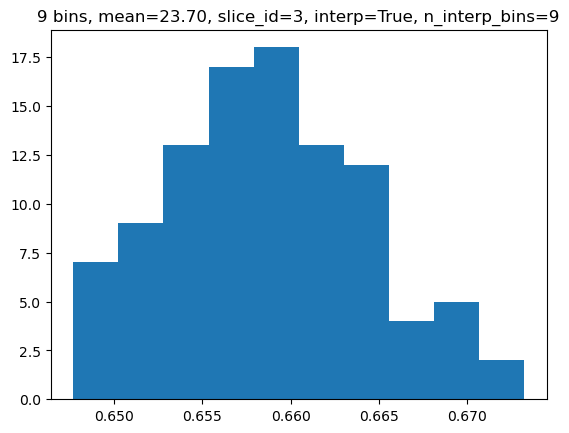

In [411]:
plt.hist(est_var)
plt.title(f'{num_bins} bins, mean={rate_map_1d.mean():.2f}, slice_id={slice_1d}, interp={interp}, n_interp_bins={n_interp_bins}')
plt.show()
# the nonselective dimension

In [156]:
est_var.mean()

-5.633568393077369

In [45]:
# and lemme check the selective dimension

slice_1d_s = 7

rate_map_1d_s = rate_map[:, slice_1d_s]
occ_1d_s = occ[:, slice_1d_s]
raw_visits_1d_s = raw_visits[:, slice_1d_s]

rate_map_1d_s

array([ 5.35207101,  6.18218085,  9.00523218, 13.93739703, 24.41780822,
       33.94558824, 29.59548255, 18.82360571, 10.70472441,  7.08935129,
        5.73124147,  5.18024691,  4.98489011,  4.94965278,  5.14939024])

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:00<00:00, 1430.47it/s]


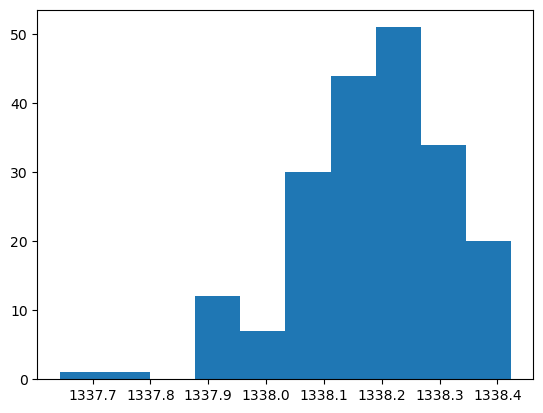

In [46]:
n_splits = 200
est_var_s = np.zeros((n_splits))

for i in tqdm(range(n_splits)):
    total_mean, train_mean, test_mean, _, _ = get_splits(raw_visits_1d_s[:, :, np.newaxis], min_visits=2, cap=False, seed=i)
    est_var_s[i] = quantify_variance_1d(train_mean, test_mean)[0]

plt.hist(est_var_s)
plt.show()
# the selective dimension

In [413]:
import numpy as np

# --- 1. The Correctly Implemented 2D Estimator ---
def calculate_explained_variance_2d_corrected(
    heatmap_train, heatmap_test, axis, verbose=False
):
    """
    Correctly implements the 2D debiased variance estimator.
    axis=0: Analyzes variable on rows (s1).
    axis=1: Analyzes variable on columns (s2).
    """
    # CRITICAL STEP: To get the marginal for a variable on one axis,
    # we must average over the OTHER axis.
    marginal_axis_to_average = 1 if axis == 1 else 0

    # Calculate marginals by averaging over the correct axis.
    f_bar = np.nanmean(heatmap_train, axis=marginal_axis_to_average, keepdims=True)
    ft_bar = np.nanmean(heatmap_test, axis=marginal_axis_to_average, keepdims=True)

    # The four terms from the formula C
    term1 = (heatmap_train - f_bar)**2
    term2 = (heatmap_test - ft_bar)**2
    term3 = (heatmap_test - heatmap_train)**2
    term4 = (f_bar - ft_bar)**2

    total_sum = np.nansum(term1 + term2 - term3 + term4)
    estimator = 0.5 * total_sum
    
    # Estimator can and should be negative for some splits.
    return estimator

# --- 2. Simulation Setup ---
num_bins = 7
n_samples = 50000
n_splits = 100
rng = np.random.default_rng(42)

# Generate random stimulus points
s1 = rng.uniform(0, 1, n_samples)
s2 = rng.uniform(0, 1, n_samples)

# Define a tuning curve ONLY for s1. s2 is non-selective.
true_tuning_s1 = 30 * np.exp(-((s1 - 0.5)**2) / (2 * 0.1**2))
base_rate = 5
true_rates = base_rate + true_tuning_s1 # Rate depends only on s1

# Generate Poisson spike counts for each sample
spike_counts = rng.poisson(true_rates)

# Digitize stimulus into bins
bin_edges = np.linspace(0, 1, num_bins + 1)
s1_binned = np.digitize(s1, bin_edges) - 1
s2_binned = np.digitize(s2, bin_edges) - 1

# --- 3. Main Loop ---
est_var_s1 = np.zeros(n_splits)
est_var_s2 = np.zeros(n_splits)

print("Running simulations...")
for i in range(n_splits):
    # For each bin, split the samples into train/test
    heatmap_train = np.full((num_bins, num_bins), np.nan)
    heatmap_test = np.full((num_bins, num_bins), np.nan)
    
    for r in range(num_bins):
        for c in range(num_bins):
            # Find all spikes that occurred in this 2D bin
            idx_in_bin = (s1_binned == r) & (s2_binned == c)
            spikes_in_bin = spike_counts[idx_in_bin]
            
            if len(spikes_in_bin) >= 2:
                # Shuffle and split into two halves
                rng.shuffle(spikes_in_bin)
                half = len(spikes_in_bin) // 2
                heatmap_train[r, c] = np.mean(spikes_in_bin[:half])
                heatmap_test[r, c] = np.mean(spikes_in_bin[half:])

    # Run the estimator on the 2D maps
    est_var_s1[i] = calculate_explained_variance_2d_corrected(
        heatmap_train, heatmap_test, axis=0
    )
    est_var_s2[i] = calculate_explained_variance_2d_corrected(
        heatmap_train, heatmap_test, axis=1
    )

# --- 4. Results ---
mean_ev_s1 = np.mean(est_var_s1)
mean_ev_s2 = np.mean(est_var_s2)

print("\n--- Final Results ---")
print(f"Selective Dimension (s1):   Mean Estimated Variance = {mean_ev_s1:.4f}")
print(f"Non-Selective Dimension (s2): Mean Estimated Variance = {mean_ev_s2:.4f}")

if mean_ev_s1 > 0 and abs(mean_ev_s2) < (0.05 * mean_ev_s1):
    print("\n✅ Success! The estimator correctly finds a high variance for s1 and near-zero for s2.")
else:
    print("\n❌ Failure. The estimator is not performing as expected.")

Running simulations...

--- Final Results ---
Selective Dimension (s1):   Mean Estimated Variance = 4491.9910
Non-Selective Dimension (s2): Mean Estimated Variance = -0.4962

✅ Success! The estimator correctly finds a high variance for s1 and near-zero for s2.


In [442]:
def calculate_explained_variance_2d_final(
    heatmap_train, heatmap_test,
    occupancy_train, occupancy_test,
    axis, verbose=False
):
    """
    Calculates debiased explained variance using an occupancy-weighted average
    to correct for non-uniform sampling.
    """
    marginal_axis_to_average = 1 if axis == 1 else 0

    mask_train = ~np.isnan(heatmap_train)
    mask_test = ~np.isnan(heatmap_test)

    # Calculate weighted marginal for the training set
    f_bar = np.average(
        heatmap_train[mask_train],
        axis=marginal_axis_to_average, # This needs careful broadcasting
        weights=occupancy_train[mask_train]
    )
    
    # For train set
    f_bar_num = np.nansum(heatmap_train * occupancy_train, axis=marginal_axis_to_average, keepdims=True)
    f_bar_den = np.nansum(occupancy_train, axis=marginal_axis_to_average, keepdims=True)
    f_bar = np.divide(f_bar_num, f_bar_den, out=np.full_like(f_bar_num, np.nan), where=f_bar_den>0)

    # For test set
    ft_bar_num = np.nansum(heatmap_test * occupancy_test, axis=marginal_axis_to_average, keepdims=True)
    ft_bar_den = np.nansum(occupancy_test, axis=marginal_axis_to_average, keepdims=True)
    ft_bar = np.divide(ft_bar_num, ft_bar_den, out=np.full_like(ft_bar_num, np.nan), where=ft_bar_den>0)

    # The rest of the formula remains the same
    term1 = (heatmap_train - f_bar)**2
    term2 = (heatmap_test - ft_bar)**2
    term3 = (heatmap_test - heatmap_train)**2
    term4 = (f_bar - ft_bar)**2

    total_sum = np.nansum(term1 + term2 - term3 + term4)
    estimator = 0.5 * total_sum
    
    return estimator
